# 02 - Baseline Model: TF-IDF + Random Forest

This notebook establishes a baseline for Adverse Drug Reaction (ADR) detection 
before moving to transformer-based models. We vectorize cleaned text with 
TF-IDF and train a Random Forest classifier as our benchmark.

In [3]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Ensure consistent, reproducible results across runs
RANDOM_STATE = 42

## 1. Data Loading

Load the four processed CSVs. Because the source text was cleaned (punctuation 
stripped, lowercased), a small number of rows may have become empty strings 
during Notebook 01 — when re-read by pandas these can be parsed as `NaN`. 
We defensively check for and handle this to avoid crashing the vectorizer.

In [7]:
# Load train/test splits from processed data directory
X_train = pd.read_csv(r"D:\adr-detection-project\data\processed\X_train.csv")
X_test = pd.read_csv(r"D:\adr-detection-project\data\processed\X_test.csv")
y_train = pd.read_csv(r"D:\adr-detection-project\data\processed\y_train.csv")
y_test = pd.read_csv(r"D:\adr-detection-project\data\processed\y_test.csv")

# Print shapes to sanity-check the load
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

X_train.head()

X_train shape: (18812, 1)
X_test shape:  (4704, 1)
y_train shape: (18812, 1)
y_test shape:  (4704, 1)


,Cleaned_Sentence
0,the septal defect repaired surgically by hazel...
1,on admission the patient showed signs of incip...
2,the ecg monitoring revealed sinus pause with m...
3,clinical and electrodiagnostic findings are di...
4,we present a patient who developed extensive m...


In [8]:
# Adjust the column name below if your Notebook 01 export used a different
# header (e.g. "text" instead of the default index column name).
TEXT_COL = X_train.columns[-1]   # assumes text is the last/only real column
LABEL_COL = y_train.columns[-1]

X_train_text = X_train[TEXT_COL]
X_test_text = X_test[TEXT_COL]
y_train_labels = y_train[LABEL_COL]
y_test_labels = y_test[LABEL_COL]

# Check for NaNs introduced by empty-string rows during CSV round-trip
print("NaNs in X_train:", X_train_text.isna().sum())
print("NaNs in X_test:", X_test_text.isna().sum())

# Replace any NaN text with an empty string rather than dropping rows,
# so X and y stay aligned (dropping rows would desync the label arrays)
X_train_text = X_train_text.fillna("")
X_test_text = X_test_text.fillna("")

NaNs in X_train: 0
NaNs in X_test: 0


## 2. TF-IDF Vectorization

We `fit_transform` the vectorizer **only on the training set**, then `transform` 
(not fit) the test set using that same fitted vocabulary/IDF weights.

**Why not fit on the test set too?**
Fitting `TfidfVectorizer` on the test set would let its vocabulary and inverse 
document frequency (IDF) statistics "see" the distribution of the test data. 
This is a form of **data leakage** — it leaks information about the evaluation 
set into training, producing metrics that are overly optimistic and do not 
reflect how the model would perform on genuinely unseen clinical text in 
production. The vectorizer must treat the test set exactly like real-world, 
never-before-seen input: transform only, using vocabulary learned from training.

In [9]:
# Initialize TF-IDF vectorizer
# - max_features caps vocabulary size to control dimensionality/memory
# - ngram_range=(1,2) captures useful clinical bigrams (e.g. "chest pain")
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words="english",
)

# Fit + transform on training text ONLY
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)

# Transform (do NOT fit) the test text using the training vocabulary
X_test_tfidf = tfidf_vectorizer.transform(X_test_text)

print(f"TF-IDF train matrix shape: {X_train_tfidf.shape}")
print(f"TF-IDF test matrix shape:  {X_test_tfidf.shape}")

TF-IDF train matrix shape: (18812, 5000)
TF-IDF test matrix shape:  (4704, 5000)


## 3. Model Training — Random Forest Baseline

In [10]:
# Initialize Random Forest with reasonable defaults for a baseline
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    random_state=RANDOM_STATE,
    n_jobs=-1,          # use all available CPU cores
    class_weight="balanced",  # ADR datasets are often imbalanced
)

# Train on the TF-IDF-vectorized training data
rf_model.fit(X_train_tfidf, y_train_labels)

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## 4. Evaluation

Predict on the held-out test set and generate a classification report 
(precision, recall, F1-score per class).

In [11]:
# Generate predictions on the test set
y_pred = rf_model.predict(X_test_tfidf)

# Print full classification report
print("Classification Report — Baseline Random Forest\n")
print(classification_report(
    y_test_labels,
    y_pred,
    target_names=["No Reaction (0)", "Adverse Reaction (1)"],
))

Classification Report — Baseline Random Forest

                      precision    recall  f1-score   support

     No Reaction (0)       0.90      0.95      0.93      3340
Adverse Reaction (1)       0.86      0.74      0.80      1364

            accuracy                           0.89      4704
           macro avg       0.88      0.85      0.86      4704
        weighted avg       0.89      0.89      0.89      4704



## 5. Visualization — Confusion Matrix

A heatmap makes it easy to see false negatives (missed ADRs), which are the 
highest-risk error type for a clinical decision support system.

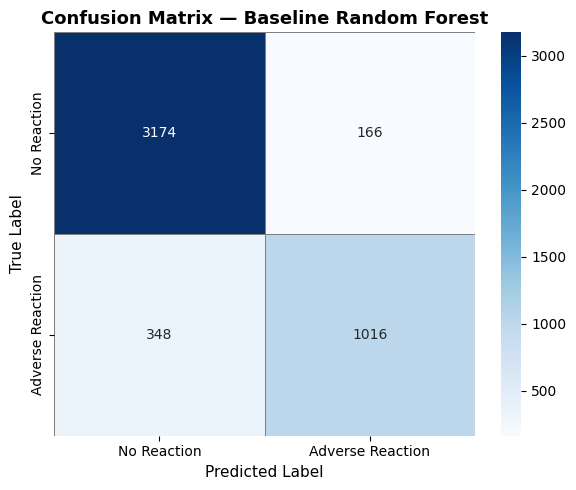

In [12]:
# Compute confusion matrix
cm = confusion_matrix(y_test_labels, y_pred)

# Plot as a formatted heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    xticklabels=["No Reaction", "Adverse Reaction"],
    yticklabels=["No Reaction", "Adverse Reaction"],
    linewidths=0.5,
    linecolor="gray",
)
plt.title("Confusion Matrix — Baseline Random Forest", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("True Label", fontsize=11)
plt.tight_layout()
plt.show()

## 6. Model Serialization

Save both the trained classifier and the fitted TF-IDF vectorizer. Both are 
required at inference time — the Streamlit dashboard must transform raw 
clinical text using the *same* fitted vectorizer before feeding it to the model.

In [16]:
# Save the trained Random Forest model
model_path = "../models/baseline_random_forest.joblib"
joblib.dump(rf_model, model_path)

# Save the fitted TF-IDF vectorizer (required to transform new text consistently)
vectorizer_path = "../models/tfidf_vectorizer.joblib"
joblib.dump(tfidf_vectorizer, vectorizer_path)

print(f"Model saved to:      {model_path}")
print(f"Vectorizer saved to: {vectorizer_path}")

Model saved to:      ../models/baseline_random_forest.joblib
Vectorizer saved to: ../models/tfidf_vectorizer.joblib
